# Exploratory analysis: when does a price drop?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
lowess = sm.nonparametric.lowess

pd.set_option('display.max_columns', None)

df = pd.read_parquet("model_dataset.parquet")

In [ ]:
display(df.head())

,itinerary_id,price_datetime,price,departure_date,dtd,bucket,window_N,n_future,wait,cost_wait,window_min,airline_name,flight_number,aircraft,src,dst,region_from,region_to,travel_time,emissions,dep_hour,dep_dayofweek,dep_month,is_weekend,season
0,W62426-2025-07-07-VNO-BUD,2025-05-04 13:04:58.999581,59.990002,2025-07-07,64,90,20,2,1,55.990002,49.990002,Wizz Air,W62426,Airbus A321neo,VNO,BUD,Baltics,Eastern,105,68310.0,9,0,7,0,2
1,LO784-2025-07-07-RIX-WAW,2025-05-04 13:04:58.999629,126.320000,2025-07-07,64,90,20,2,0,136.320007,136.320007,LOT,LO784,Embraer 175,RIX,WAW,Baltics,Eastern,80,91575.0,14,0,7,0,2
2,BT491-2025-07-07-RIX-BUD,2025-05-04 13:04:58.999664,140.320007,2025-07-07,64,90,20,2,1,78.320000,78.320000,Air Baltic,BT491,Airbus A220-300 Passenger,RIX,BUD,Baltics,Eastern,115,117673.0,11,0,7,0,2
3,LO794-2025-07-07-RIX-WAW,2025-05-04 13:04:58.999692,116.320000,2025-07-07,64,90,20,2,0,126.320000,126.320000,LOT,LO794,Embraer 195,RIX,WAW,Baltics,Eastern,80,82664.0,5,0,7,0,2
4,BT481-2025-07-07-RIX-PRG,2025-05-04 13:04:58.999715,121.320000,2025-07-07,64,90,20,2,0,121.320000,121.320000,Air Baltic,BT481,Airbus A220-300 Passenger,RIX,PRG,Baltics,Eastern,110,107799.0,7,0,7,0,2


## Route map
Flights to and from Vilnius (VNO).

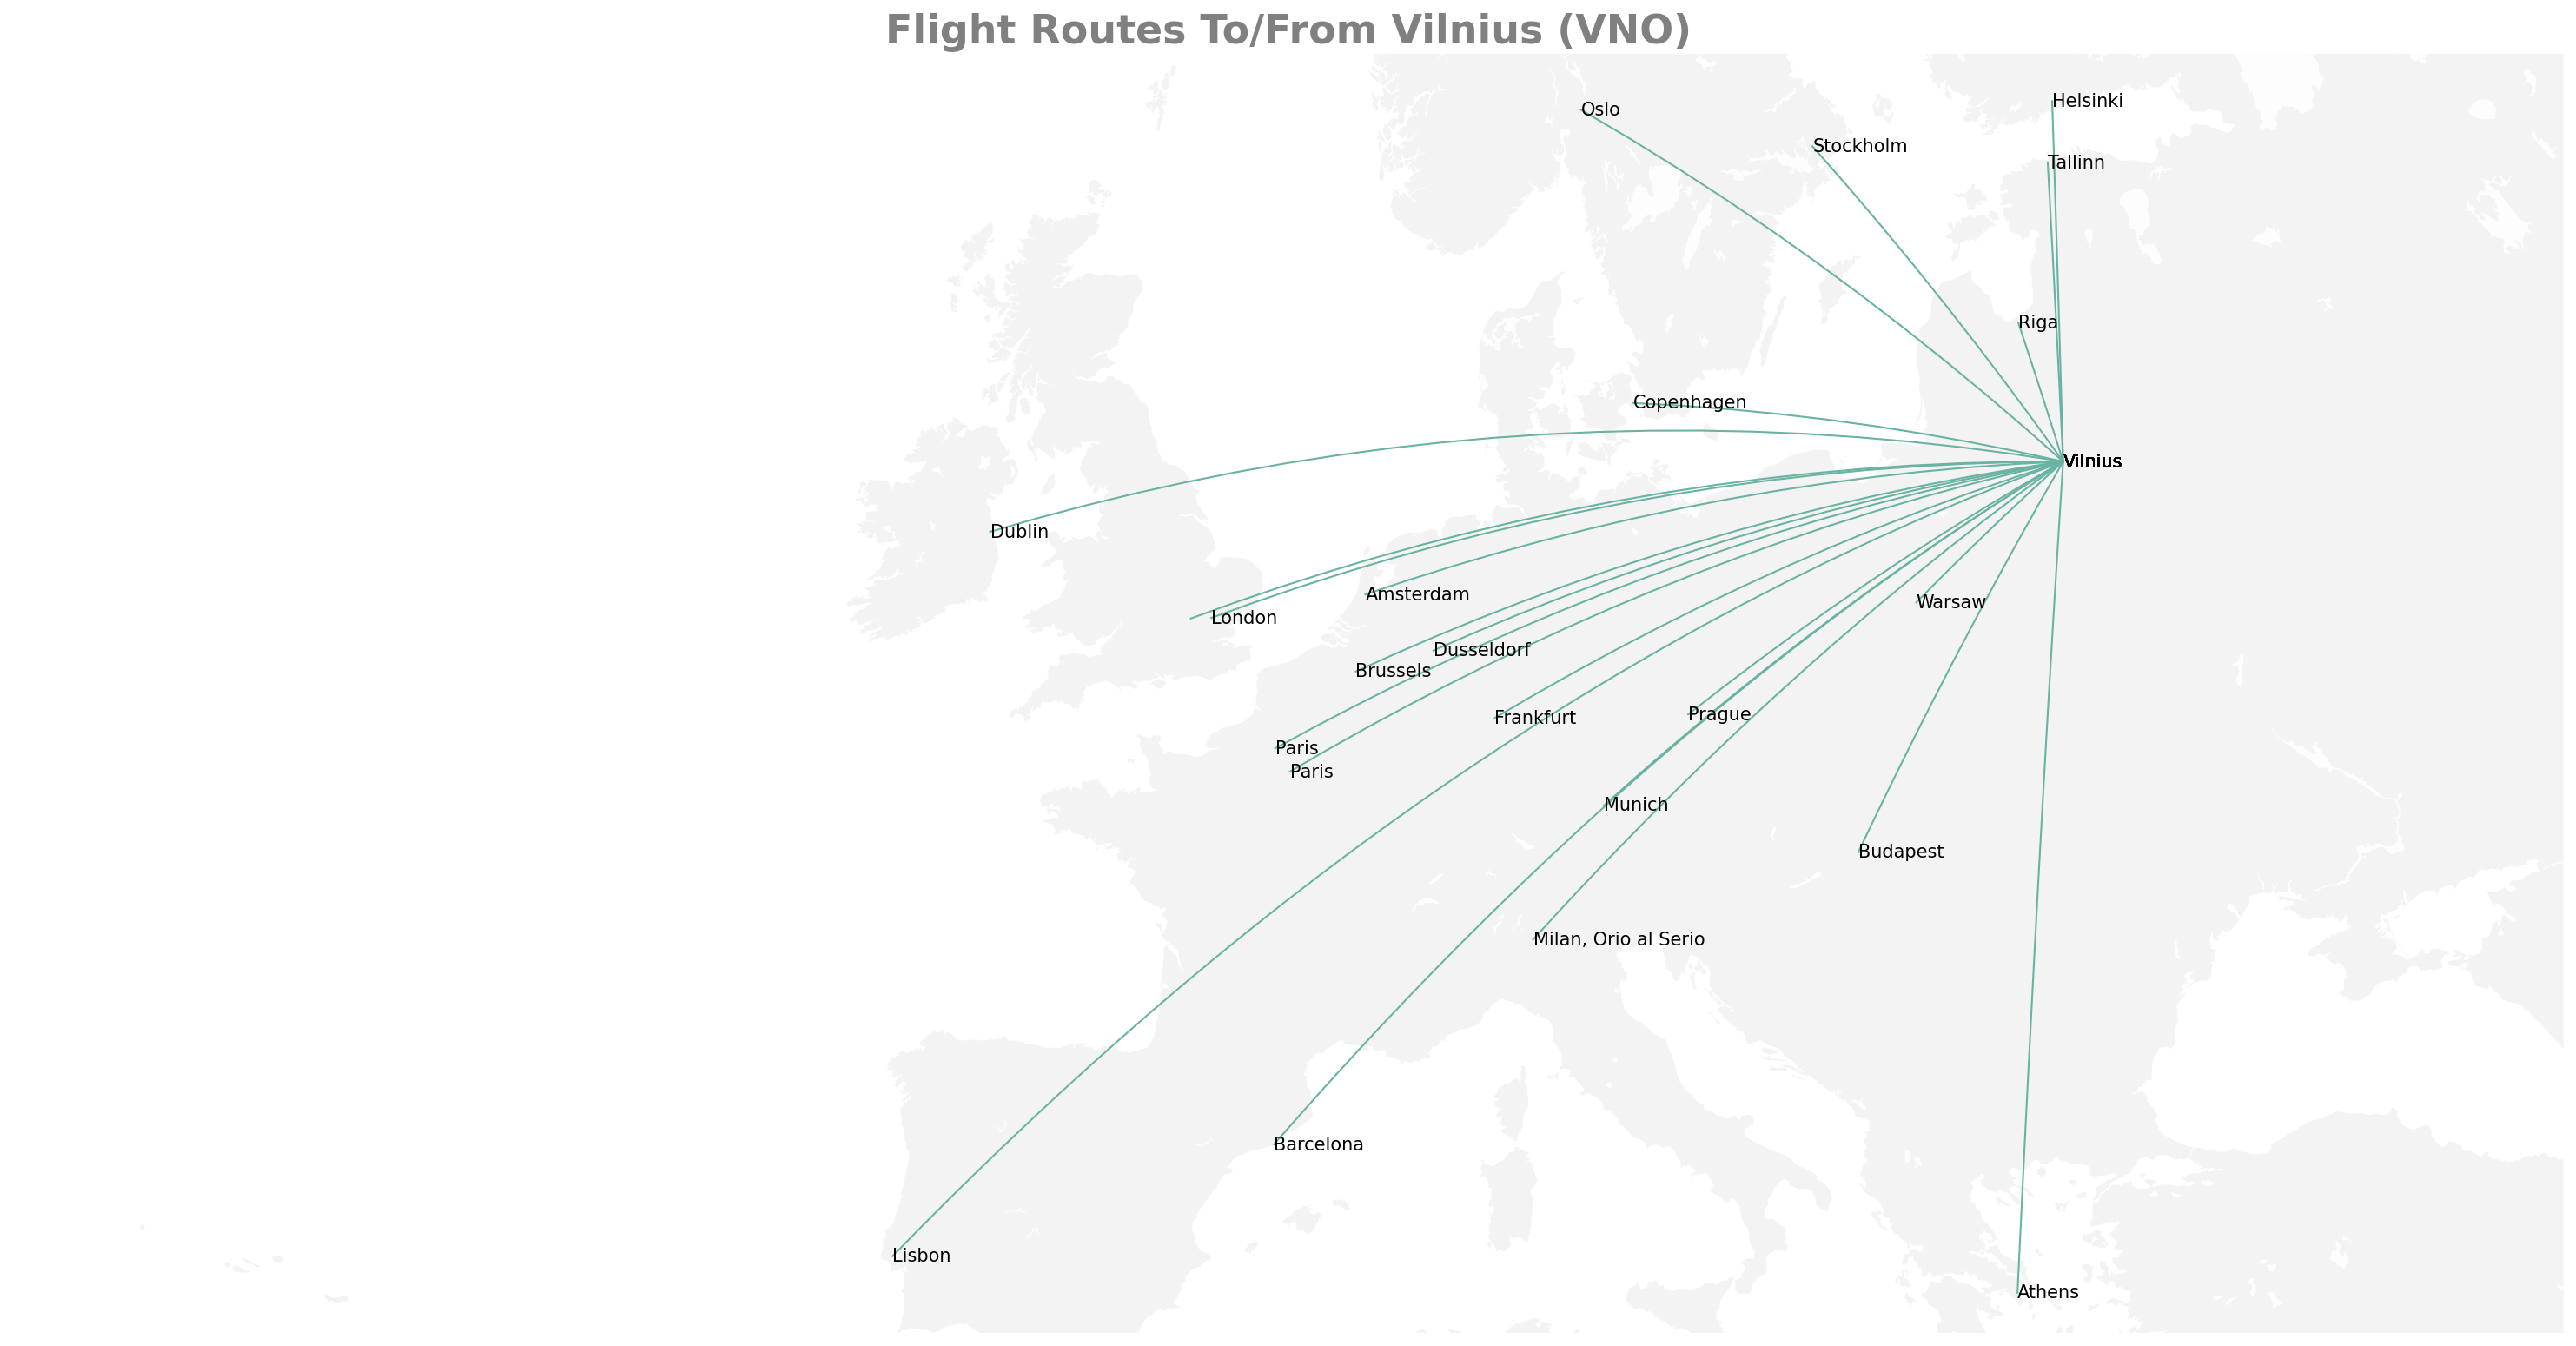

In [ ]:
from mpl_toolkits.basemap import Basemap

ICAO_CSV_PATH = r"F:\pet-projects\google-flight-scraper\demand_scraping\iata-icao.csv"   # airport coordinates lookup

icao_codes_df = pd.read_csv(ICAO_CSV_PATH).dropna().drop_duplicates(subset=["iata"])
coordinates_dict = icao_codes_df.set_index("iata")[["latitude", "longitude", "Ciudad / Location"]].to_dict(orient="index")

# NOTE: merged_df is created in the Ryanair section below; run that cell first.
# Undirected route key, so that A-B and B-A count as the same route
merged_df["sorted_route"] = merged_df.apply(lambda row: "-".join(sorted([row["src"], row["dst"]])), axis=1)
unique_routes = merged_df[["src", "dst", "sorted_route"]].drop_duplicates(subset=["sorted_route"]).reset_index(drop=True)
unique_routes = unique_routes[["src", "dst"]].to_dict(orient="records")

# Keep only routes that start or end in Vilnius (VNO)
unique_routes = [route for route in unique_routes if "VNO" in (route["src"], route["dst"])]

plt.figure(figsize=(20, 12), dpi=150)
plt.title("Flight Routes To/From Vilnius (VNO)",
          fontsize=22,
          fontweight="bold",
          color="gray",
          loc="center")
plt.tight_layout(pad=0)

# Background map
m = Basemap(llcrnrlon=-35,   # lower-left longitude
            llcrnrlat=37,    # lower-left latitude
            urcrnrlon=40,    # upper-right longitude
            urcrnrlat=61,    # upper-right latitude
            resolution="i",
            projection="merc")
m.drawmapboundary(fill_color="white", linewidth=0)
m.fillcontinents(color="#f2f2f2", alpha=0.9)
m.drawcoastlines(linewidth=0.1, color="white")

for route in unique_routes:
    src, dst = route["src"], route["dst"]

    if src in coordinates_dict and dst in coordinates_dict:
        src_coords = coordinates_dict[src]
        dst_coords = coordinates_dict[dst]

        m.drawgreatcircle(src_coords["longitude"], src_coords["latitude"],
                          dst_coords["longitude"], dst_coords["latitude"],
                          linewidth=1, color="#69b3a2")

        # Label both endpoints (London Luton is skipped to avoid clutter)
        if dst_coords["Ciudad / Location"] != "London, Luton":
            plt.annotate(dst_coords["Ciudad / Location"],
                         xy=m(dst_coords["longitude"], dst_coords["latitude"]),
                         verticalalignment="center")
            plt.annotate(src_coords["Ciudad / Location"],
                         xy=m(src_coords["longitude"], src_coords["latitude"]),
                         verticalalignment="center")

**Route map.** Vilnius connects to about 20 cities in the data

C:\Users\Daniil\AppData\Local\Temp\ipykernel_14972\1846361132.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data = df.groupby(["airline_name", "bucket"])['wait'].mean().unstack('bucket')


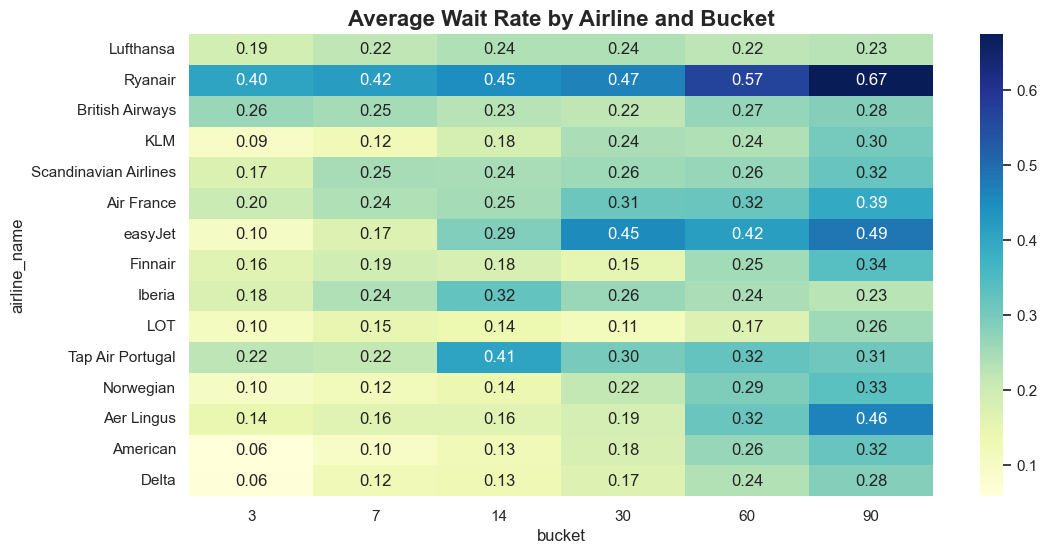

In [48]:
# 1. Wait rate by airline × bucket. This is the rule baseline from last time and the most important table.
data = df.groupby(["airline_name", "bucket"])['wait'].mean().unstack('bucket')

top = df["airline_name"].value_counts().index[:15]
data = data.loc[top]


plt.figure(figsize=(12, 6))
sns.heatmap(data, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Wait Rate by Airline and Bucket", fontsize=16, weight='bold')
plt.show()


Ryanair stands out!
Its wait rate rises from 0.40 (2–3 days) to **0.67** (61–90 days), above the 0.46 break-even. easyJet goes from 0.10 to 0.49. Network carriers stay flat around 0.2–0.3 at every horizon (Lufthansa 0.19–0.24, LOT 0.10–0.26). Low-cost carriers price dynamically and cut fares often and network carriers keep their prices steadier.

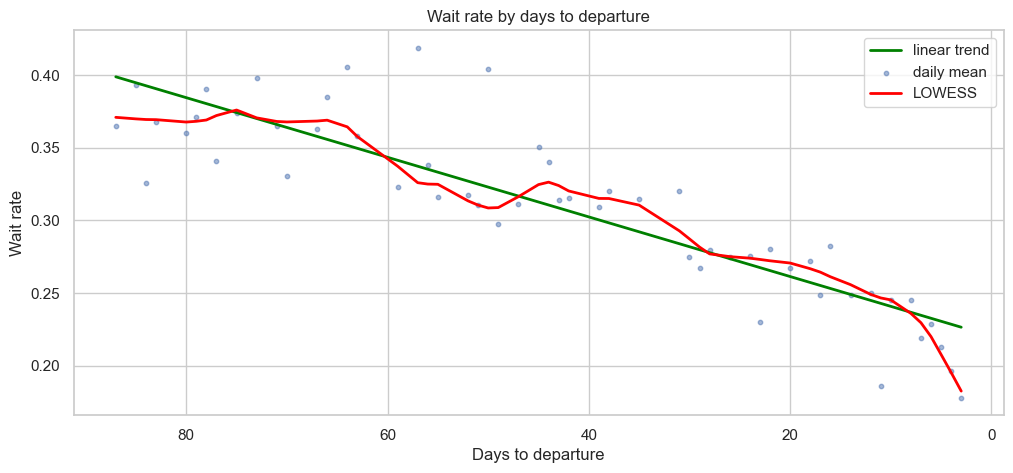

54 3 87
count        54.000000
mean     240250.388889
std      202048.329732
min         206.000000
25%        2279.250000
50%      390669.500000
75%      404822.750000
max      504092.000000
Name: n, dtype: float64


In [70]:
# 2. Wait rate by days to dep

g = df.groupby("dtd")["wait"].agg(rate="mean", n="size")
smooth = lowess(g["rate"], g.index, frac=0.13)            # returns sorted [x, y] pairs

fig, ax = plt.subplots(figsize=(12, 5))

trend = np.polyfit(g.index, g["rate"], 1)                  # linear trend line
ax.plot(g.index, np.polyval(trend, g.index), color="green", lw=2, label="linear trend")
ax.scatter(g.index, g["rate"], s=10, alpha=0.5, label="daily mean")
ax.plot(smooth[:, 0], smooth[:, 1], color="red", lw=2, label="LOWESS")
ax.invert_xaxis()                                          # time flows toward departure
ax.set_xlabel("Days to departure"); ax.set_ylabel("Wait rate")
ax.set_title("Wait rate by days to departure"); ax.legend(); plt.show()

print(len(g), g.index.min(), g.index.max())
print(g["n"].describe())


The wait rate is flat around 0.37 from 90 to about 65 days, then falls steadily to 0.18 three days before departure. The closer the flight, the less likely a drop. 

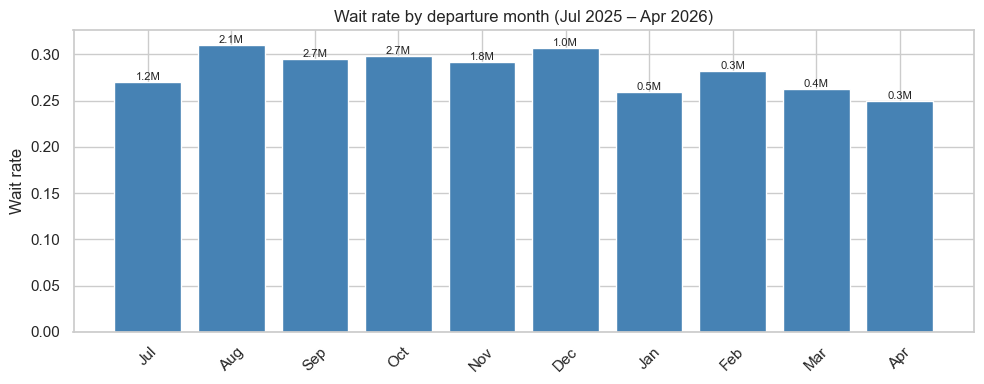

In [ ]:
# 3. Wait rate by departure month

from calendar import month_abbr

df["dep_ym"] = df["departure_date"].dt.to_period("M")

m = df.groupby("dep_ym").agg(wait_rate=("wait", "mean"), n=('wait', 'size'))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(m.index.astype(str), m["wait_rate"], color="steelblue")
for i, (r, n) in enumerate(zip(m["wait_rate"], m["n"])):
    ax.text(i, r, f"{n/1e6:.1f}M", ha="center", va="bottom", fontsize=8)   # rows per month
ax.set_title("Wait rate by departure month (Jul 2025 – Apr 2026)")
ax.set_ylabel("Wait rate")
plt.xticks(ticks=range(len(m)), labels=[month_abbr[i] for i in m.index.month], rotation=45); plt.tight_layout(); plt.show()


The wait rate is fairly flat (0.25–0.31) across months. Seasonality moves the **price level** (summer is expensive), but not much the **chance of a drop**.

C:\Users\Daniil\AppData\Local\Temp\ipykernel_14972\2350106250.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data = df.groupby(["region_from", "region_to"])['wait'].mean().unstack('region_to')


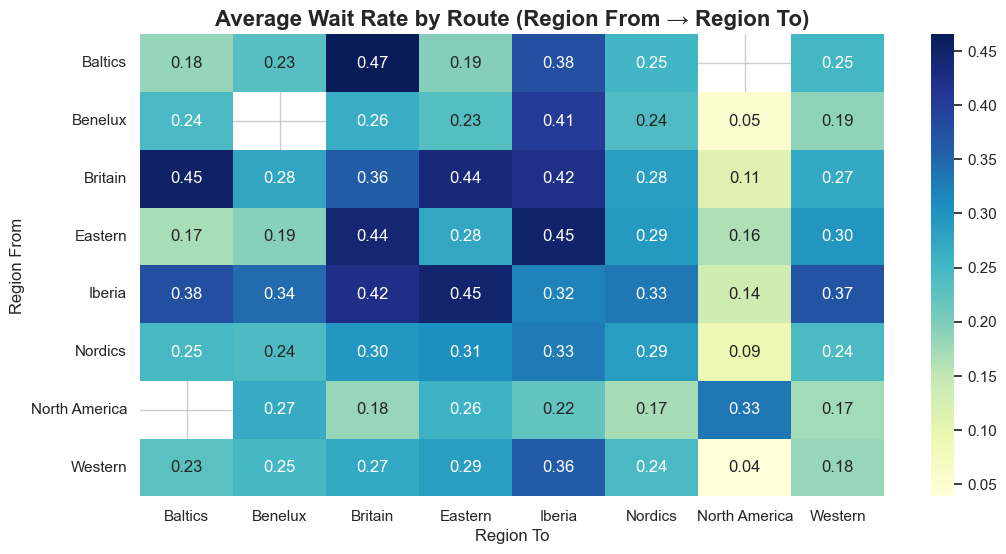

In [74]:
# 4. Wait rate by route and region (region_from, region_to).

data = df.groupby(["region_from", "region_to"])['wait'].mean().unstack('region_to')

plt.figure(figsize=(12, 6))
sns.heatmap(data, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Wait Rate by Route (Region From → Region To)", fontsize=16, weight='bold')
plt.xlabel("Region To"); plt.ylabel("Region From")
plt.show()

- Routes to and from Britain, Iberia and the Baltics show the highest wait rates (0.38–0.47). Routes to North America show the lowest (0.04–0.16). 
- This mostly reflects that European routes are dominated by low-cost carriers, transatlantic ones by network carriers. Region adds little beyond airline.

            wait_rate        n
chg_bin                       
<-20            0.253   528346
-20..-10        0.325   692988
-10..-3         0.399   554790
-3..0           0.251  1606409
0               0.225  3274753
0..3            0.239  1677485
3..10           0.349   836251
10..20          0.333  1204925
>20             0.409  1531015
first seen      0.338  1066559


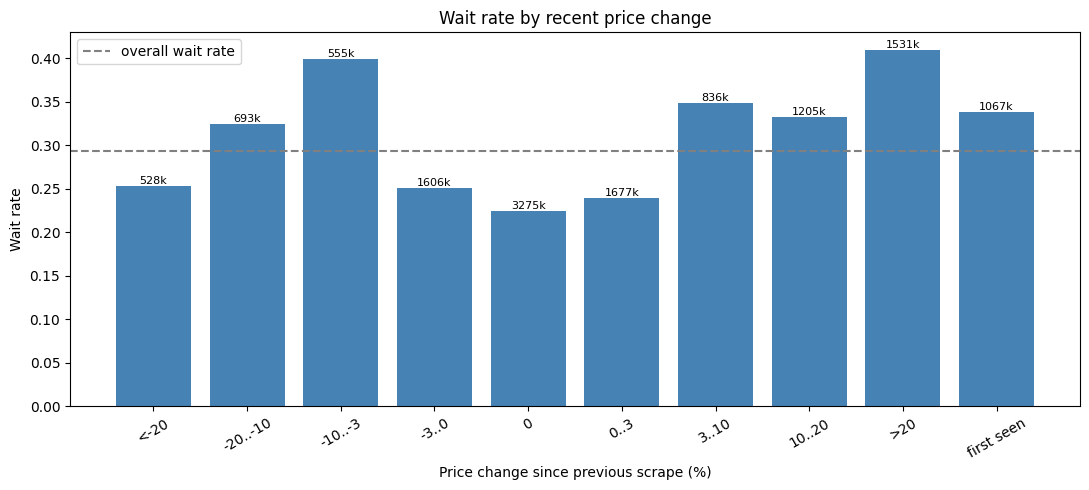

bucket        3     7     14    30    60    90
chg_bin                                       
<-20        0.21  0.21  0.21  0.23  0.27  0.31
-20..-10    0.26  0.27  0.29  0.31  0.33  0.39
-10..-3     0.33  0.35  0.36  0.39  0.40  0.47
-3..0       0.13  0.18  0.19  0.24  0.27  0.33
0           0.11  0.16  0.20  0.21  0.23  0.30
0..3        0.12  0.16  0.18  0.22  0.25  0.31
3..10       0.20  0.22  0.26  0.33  0.41  0.51
10..20      0.17  0.21  0.24  0.33  0.41  0.54
>20         0.33  0.32  0.35  0.40  0.47  0.60
first seen  0.21  0.19  0.23  0.27  0.32  0.37


In [4]:
# 5. Wait rate by price relative to the itinerary's own earlier prices (using past points only). 
# If "the price just jumped up" predicts a later drop, that's your best feature, and it's the one generic EDA never shows.

df_sorted = df.sort_values(["itinerary_id", "price_datetime"])
df_sorted["prev_price"] = df_sorted.groupby("itinerary_id")["price"].shift(1)
df_sorted["price_diff%"] = (df_sorted["price"] - df_sorted["prev_price"]) / df_sorted["prev_price"] * 100

bins = [-np.inf, -20, -10, -3, -0.01, 0.01, 3, 10, 20, np.inf]
labels = ["<-20", "-20..-10", "-10..-3", "-3..0", "0", "0..3", "3..10", "10..20", ">20"]
df_sorted["chg_bin"] = pd.cut(df_sorted["price_diff%"], bins=bins, labels=labels)
df_sorted["chg_bin"] = df_sorted["chg_bin"].cat.add_categories("first seen").fillna("first seen")

t = df_sorted.groupby("chg_bin", observed=True)["wait"].agg(wait_rate="mean", n="size")
print(t.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(t.index.astype(str), t["wait_rate"], color="steelblue")
for i, (r, n) in enumerate(zip(t["wait_rate"], t["n"])):
    ax.text(i, r, f"{n/1e3:.0f}k", ha="center", va="bottom", fontsize=8)
ax.axhline(df_sorted["wait"].mean(), color="grey", ls="--", label="overall wait rate")
ax.set_xlabel("Price change since previous scrape (%)"); ax.set_ylabel("Wait rate")
ax.set_title("Wait rate by recent price change"); ax.legend()
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


print(df_sorted.pivot_table(index="chg_bin", columns="bucket", values="wait",
                    aggfunc="mean", observed=True).round(2))


strongest signal found, feature should be added.
- **Flat prices stay flat**: no change → 0.23, the lowest wait rate.
- **After a jump, prices tend to come back**: +20% or more → 0.41 overall, and **0.60 at 61–90 days**.
- **Moderate drops continue**: −10 to −3% → 0.40. After a large drop (below −20%) the price is already low, so only 0.2

## 7. Price curves for a single flight

In [29]:
def filter_itin(data, flight_number=None, date_till=None):
    """Keep itineraries of one flight number and/or departing on or before `date_till`."""
    data = data.copy()
    if flight_number:
        data = data[data["itinerary_id"].str.contains(f"{flight_number}-", na=False)]
    if date_till is not None:
        data["departure_date"] = pd.to_datetime(data["departure_date"], errors="coerce")
        data = data[data["departure_date"] <= pd.Timestamp(date_till)]
    return data

def prices_for_the_route(df, flight_number, flight_date=None, exclude_date=None):
    """Price observations of one flight number, optionally for one departure date or excluding it."""
    out = df[df["flight_number"] == flight_number].copy()
    if flight_date is not None:
        out = out[out["departure_date"] == pd.Timestamp(flight_date)]
    if exclude_date is not None:
        out = out[out["departure_date"] != pd.Timestamp(exclude_date)]
    return out

def mean_curve(df, to_normalize=True, max_days=90, min_count=5):
    """Mean price per dtd, keeping only points with at least `min_count` observations.

    If `to_normalize` is True, prices are divided by the maximum price of each departure date first.
    """
    df = df.copy()
    col = "price"
    if to_normalize:
        df["normalized_price"] = df.groupby("dtd")["price"].transform(lambda x: x / x.max())
        col = "normalized_price"
    g = (df[df["dtd"] < max_days]
         .groupby("dtd")[col]
         .agg(mean="mean", n="count")
         .reset_index())
    return g[g["n"] >= min_count]

def smooth_LOWESS(df, to_normalize=False, frac=0.13, min_count=5):
    """LOWESS-smoothed mean price curve."""
    g = mean_curve(df, to_normalize, min_count=min_count)
    return lowess(g["mean"], g["dtd"], frac=frac)

def smooth_prices_rolling(df, to_normalize=False, window=3, min_count=5):
    """Centred rolling mean of the mean price curve."""
    g = mean_curve(df, to_normalize, min_count=min_count).sort_values("dtd")
    g["smoothed_price"] = g["mean"].rolling(window, center=True).mean()
    return g[["dtd", "smoothed_price"]].dropna()

Historical data points for FR103 (excluding 2025-07-20): 1061


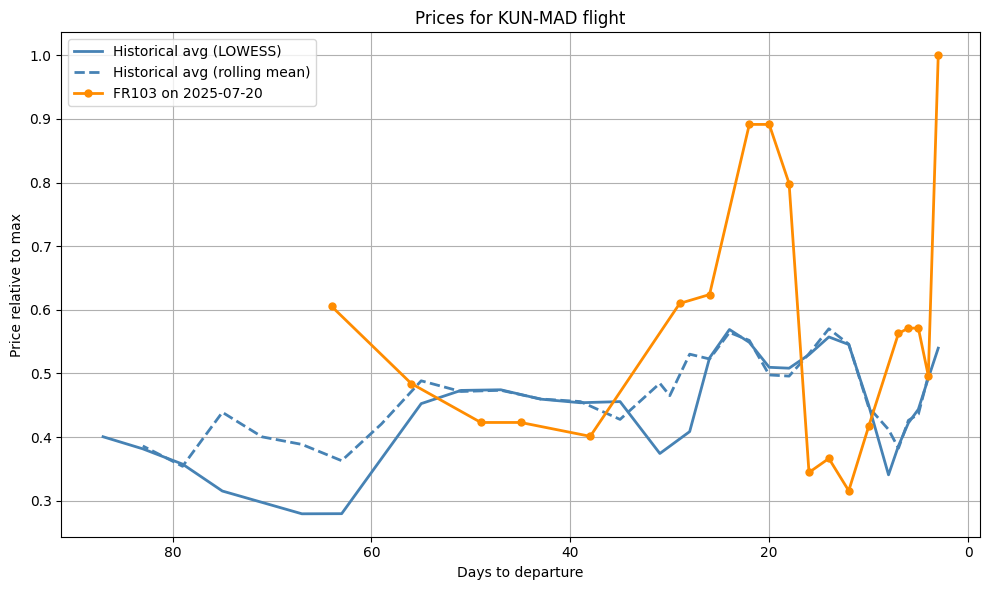

In [30]:
# Compare one departure (TARGET) with the historical average of the same flight number
TARGET = "2025-07-20"

hist = prices_for_the_route(df, "FR103", exclude_date=TARGET)
print(f"Historical data points for FR103 (excluding {TARGET}): {len(hist)}")
specific = prices_for_the_route(df, "FR103", flight_date=TARGET)

lo = smooth_LOWESS(hist, to_normalize=True)
roll = smooth_prices_rolling(hist, to_normalize=True, window=3)

specific = specific.sort_values("dtd").copy()
specific["norm"] = specific["price"] / specific["price"].max()

plt.figure(figsize=(10, 6))
plt.plot(lo[:, 0], lo[:, 1], color="steelblue", lw=2, label="Historical avg (LOWESS)")
plt.plot(roll["dtd"], roll["smoothed_price"], color="steelblue",
         ls="--", lw=2, label="Historical avg (rolling mean)")
plt.plot(specific["dtd"], specific["norm"], color="darkorange",
         marker="o", ms=5, lw=2, label=f"FR103 on {TARGET}")
plt.gca().invert_xaxis()
plt.xlabel("Days to departure"); plt.ylabel("Price relative to max")
plt.title("Prices for KUN-MAD flight")
plt.legend(); plt.grid(); plt.tight_layout(); plt.show()

### Insights: FR103 (Kaunas–Madrid)

1. **Price trend.**  The lowest price can be seen in 80-60 days window, however on individual flights real price dip can be futher away. One month before departure price tend to go high as possible to check market, if some of places still unsold - price may have sharp fall in 20-10 days before dep. After this price goes up. It suggest looking for ticket as soon as possible, if price is relatively high - we should wait, as there's high chance of falling.
2. **Booking window.** The dip around 50 days suggests this may be the cheapest time to book KUN–MAD. After sharp rises, prices often fall back (from about 20 to 15 days), which supports the goal of the model: predicting whether it is worth waiting for a cheaper ticket.

## 8. Ryanair analysis

Ryanair itineraries departing within the next 60 days.

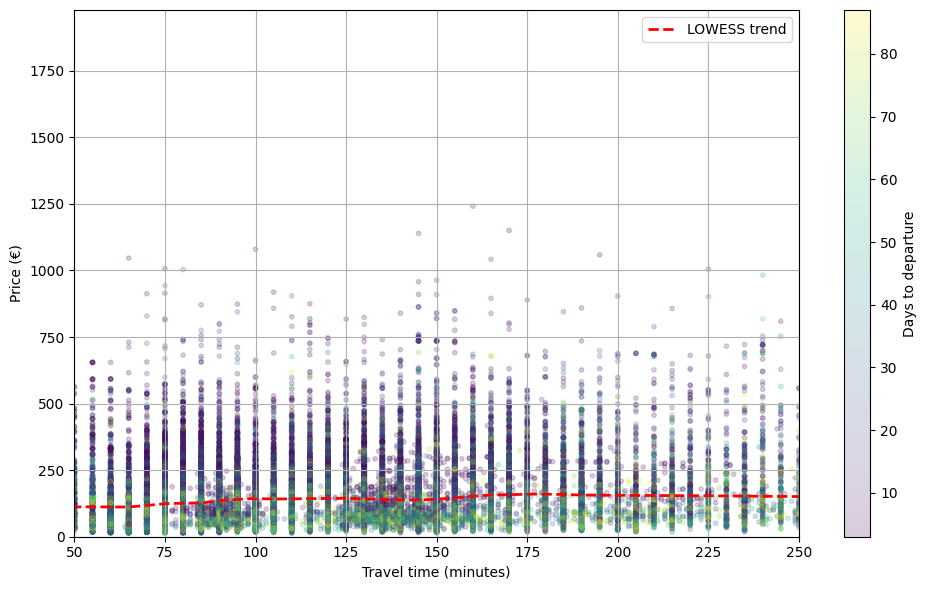

In [ ]:
def filter_for_airline(df: pd.DataFrame, airline_name: str) -> pd.DataFrame:
    """Return only the rows of one airline.

    :param df: DataFrame containing flight legs.
    :param airline_name: Name of the airline to filter by.
    """
    return df[df["airline_name"] == airline_name]

def plot_price_by_travel_time(df: pd.DataFrame, n=50_000, seed=42):
    """Scatter of price vs travel time on a random sample, with a LOWESS trend."""
    s = df.sample(min(n, len(df)), random_state=seed).sort_values("travel_time")
    trend = lowess(s["price"], s["travel_time"], frac=0.2)

    plt.figure(figsize=(10, 6))
    plt.scatter(s["travel_time"], s["price"], alpha=0.2, c=s["dtd"], cmap="viridis", s=10)
    plt.plot(trend[:, 0], trend[:, 1], color="red", lw=2, ls="--", label="LOWESS trend")
    plt.xlim(50, 250)
    plt.ylim(0, s["price"].quantile(0.99))   # the max is an outlier and squashes the plot
    plt.xlabel("Travel time (minutes)"); plt.ylabel("Price (€)")
    plt.colorbar(label="Days to departure"); plt.legend(); plt.grid(); plt.tight_layout(); plt.show()


ryanair = filter_for_airline(df, "Ryanair")

plot_price_by_travel_time(ryanair)

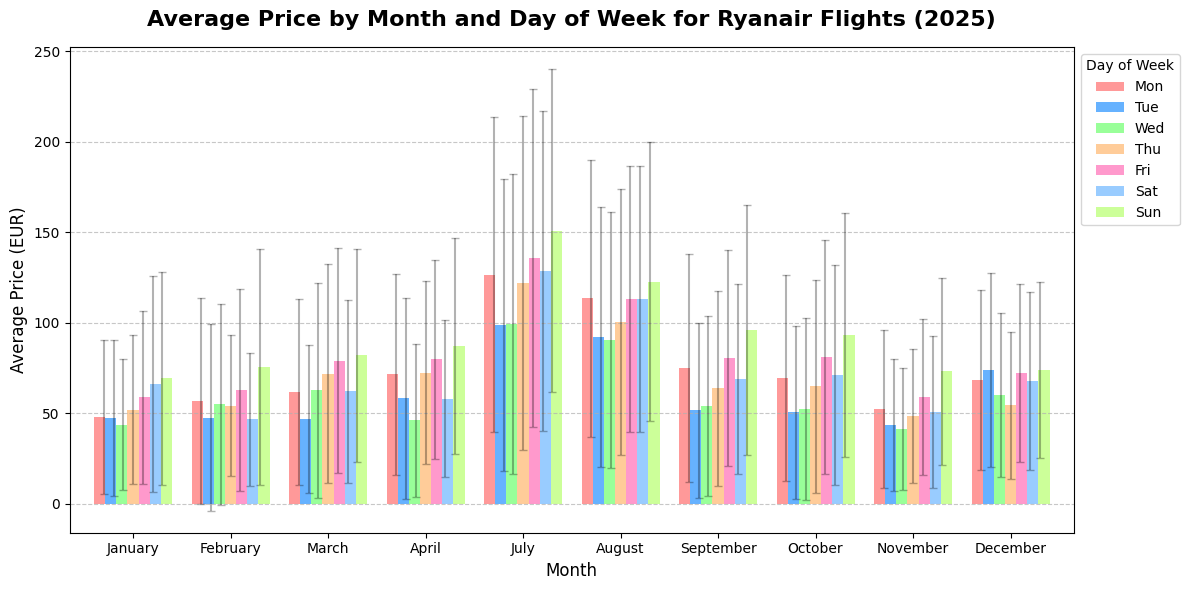

In [36]:
import calendar

data = ryanair.copy()

monthly_dayofweek_avg = data.groupby(["dep_month", "dep_dayofweek"])["price"].mean().unstack()
monthly_dayofweek_std = data.groupby(["dep_month", "dep_dayofweek"])["price"].std().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
monthly_dayofweek_avg.plot(kind="bar", ax=ax, width=0.8,
                           color=["#FF9999", "#66B2FF", "#99FF99", "#FFCC99", "#FF99CC", "#99CCFF", "#CCFF99"])

# Standard-deviation error bars, offset to line up with each day-of-week bar
for i, month in enumerate(monthly_dayofweek_avg.index):
    for j, day in enumerate(monthly_dayofweek_avg.columns):
        ax.errorbar(i + (j - 3) * 0.1, monthly_dayofweek_avg.iloc[i, j],
                    yerr=monthly_dayofweek_std.iloc[i, j], fmt="none", capsize=3, capthick=1,
                    color="black", alpha=0.3)

ax.set_title("Average Price by Month and Day of Week for Ryanair Flights (2025)", fontsize=16, weight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Average Price (EUR)", fontsize=12)
ax.set_xticks(range(len(monthly_dayofweek_avg.index)))
ax.set_xticklabels([calendar.month_name[m] for m in monthly_dayofweek_avg.index], rotation=0)
ax.legend(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], title="Day of Week",
          loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**Seasonality.** Average prices are highest in July (about 100 to 150 EUR depending on the weekday), and August is close behind. In other months they fall to about 40 to 80 EUR.

### Are night and early-morning flights cheaper?

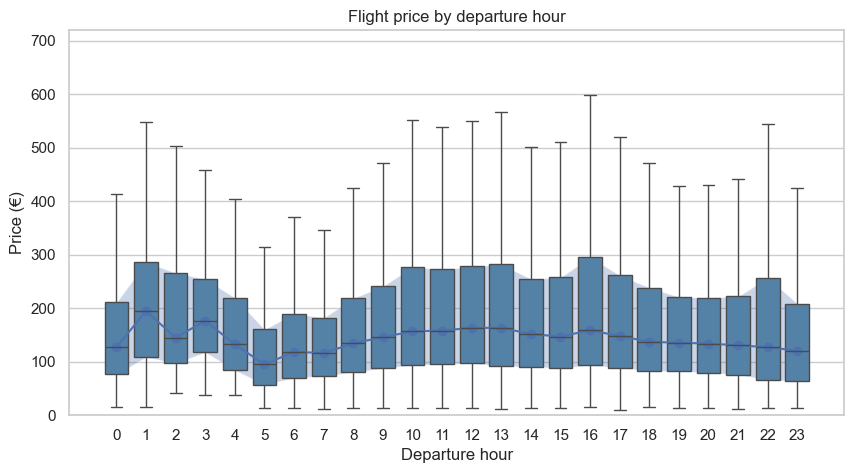

In [38]:
sns.set(style="whitegrid")

plt.figure(figsize=(10, 5))
sns.boxplot(x="dep_hour", y="price", data=df, showfliers=False, color="steelblue")
plt.ylim(0, df["price"].quantile(0.95))
plt.title("Flight price by departure hour")
plt.xlabel("Departure hour"); plt.ylabel("Price (€)")

q = df.groupby("dep_hour")["price"].quantile([0.25, 0.5, 0.75]).unstack()
plt.fill_between(q.index, q[0.25], q[0.75], alpha=0.3)
plt.plot(q.index, q[0.5], marker="o")

plt.show()




Early morning flights are tend to be less expensive. Night flights are the highest in the price